# 기능 A 꼭 넣을 문구가 문장 앞뒤에 따로 붙는 실패 고치기: 후보 6개 (세 게임, 11/03)

13·23 기록에서 0x72 "스팀 찜하기" sns 문장 90개를 보면, 실패 26개는 모두 문구를 쉼표로 따로 붙였다(문장 끝 "…, 스팀 찜하기" 19개, 문장 앞 "스팀 찜하기, …" 7개). 문구 바로 뒤에 "로"가 붙은 "스팀 찜하기로 …" 54개는 모두 통과했다(`nx_must_scored.csv`, `n8_must_scored.csv`). 23에서 샘플링 후보를 8개로 늘려도 나아지지 않았다(0x72 0.8 → 0.533).

이 노트북은 조사로 찾은 후보 6개를 같은 기준으로 비교한다. 기준은 지금 방식 ③(`n4+example+fb_specific`: 지시문 예시, 첫 생성 탐욕적 디코딩 → 샘플링 후보 4개 → 구체적 재요청 1번)이다. 후보마다 ③에서 한 곳만 바꾼다.

| 후보 | 바꾸는 곳 | 내용 | 근거 |
|---|---|---|---|
| 1 `prefill` | 재요청 단계 | store는 두고 sns 앞부분을 `"{문구}로`로 미리 넣은 뒤 모델이 이어 쓰게 함 | transformers 채팅 템플릿 문서(응답 앞부분 미리 채우기), 위 기록 54/54 |
| 2 `bad_words` | 모든 생성 | 쉼표 + 문구, 문구 + 쉼표 토큰 순서를 생성하지 못하게 막음(`bad_words_ids`) | transformers 생성 문서 |
| 3 `fb_edit` | 재요청 단계 | "sns를 '{문구}로 …'로 시작하게 고쳐 써"처럼 고칠 문장을 지시 | Self-Refine (Madaan et al. 2023) |
| 4 `dnc` | 재요청 단계 | store는 두고 sns 한 문장만 따로 다시 써서 합침 | Li et al. 2024 분할 정복 |
| 5 `template` | 지시문 | sns를 `"[앞부분], {문구}로 [뒷부분]"` 틀로 쓰게 함 | 문구 위치를 틀로 고정 |
| 6 `cbs` | 첫 생성 | 문구가 반드시 들어가는 제약 빔서치(빔 4개). transformers 5에서는 Hub 코드 `transformers-community/constrained-beam-search`로만 실행됨 | Hokamp & Liu 2017, Post & Vilar 2018 |

- 입력: 13·10·23과 같은 표본(게임마다 5장), seed 0·1·2. 꼭 넣을 문구는 냥기사 "11월 업데이트 기념 30% 할인", 0x72 "스팀 찜하기", KayKit "신규 영웅 로그 추가".
- 기준 ③은 다시 돌리지 않고 13(`nx_must_compare.csv`)·10(`kk_must_compare.csv`) 기록을 읽는다(23과 같음).
- 후보 1·3·4는 ③에서 재요청 단계까지 간 건에만 차이가 난다. 그래서 ③ 기록에서 재요청 직전의 글(`texts_all`로 ③ 규칙대로 다시 고른 글, 기록된 재요청 문장과 같은지 확인)을 그대로 넣고 재요청 단계만 다시 만든다. ③의 재요청도 같은 방식으로 다시 만들어 함께 비교한다(재요청 seed 0·1·2). 나머지 건은 ③ 결과를 그대로 쓴다.
- 후보 2·5·6은 모든 생성이나 첫 생성이 바뀌므로 15건 × seed 3개를 처음부터 다시 만든다.
- 후보 6은 Hub 코드를 내려받아 실행한다(`trust_remote_code=True`). Qwen3-VL에서 돌아가는지 확인되지 않았으므로 오류가 나면 오류를 기록에 남긴다.
- 후보 6 다시 실행 (11/03): 첫 실행은 Hub 이름(`transformers-community/constrained-beam-search`)으로 넘겨 45건 모두 `OSError: ... does not appear to have a file named custom_generate\beam_search.py`로 실행되지 않았다. transformers 5.20.1 `dynamic_module_utils.py`가 `generate.py`가 함께 쓰는 파일 이름을 `Path(...) / 파일`로 만들어 Windows에서 역슬래시가 들어가고, Hub에서는 그 이름의 파일을 찾지 못한다. 로컬 폴더로 넘기면 파일 경로를 그대로 복사하므로, 코드를 `models/hub_code/constrained-beam-search`에 받아 그 경로로 다시 실행한다. 다시 실행하면 오류 난 건만 다시 만들고 나머지는 건너뛴다.
- 검사 규칙·재요청 문구·지시문은 23과 같다.
- 기록 (`outputs/local_vlm/`, 13·10 파일은 읽기만 함)
  - `m25_config.json`, `m25_compare.csv`(후보 2·5·6), `m25_repair.csv`(재요청 단계 다시 만들기), `m25_runs.csv`
  - `m25_scored.csv`, `m25_summary.csv`, `m25_by_game.csv`, `m25_fail_types.csv`, `m25_repair_summary.csv`, `m25_compare.png`, `m25_examples.csv`
- 진행 출력: 생성은 별도 프로세스에서 하고, 모델 로드 시작·끝과 건마다 `[시각 | 경과 | VRAM] i/전체`를 바로 출력한다.
- 예상 시간: 재요청 단계 다시 만들기 7건 × 4방식 × seed 3개 = 84번 생성, 약 15분. 후보 2·5·6은 ③ 실행 1번이 seed 하나에 약 7~8분(13 `nx_must_runs.csv` 255.9~266.5초 + 10 `kk_must_runs.csv` 180.9~197.4초)이라 9번에 약 70분(제약 빔서치는 더 길 수 있음). 합계 약 1시간 30분. 실제 시간은 `m25_runs.csv`에 남는다.
- 재요청 단계 다시 만들기를 먼저 돌리고, 후보 2 → 5 → 6 순서로 돌린다. 중간에 멈춰도 다시 실행하면 끝난 건은 건너뛴다.
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 설정 (09와 같음)

In [1]:
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs' / 'local_vlm'
OUT_DIR.mkdir(parents=True, exist_ok=True)

QWEN_REPO = 'Qwen/Qwen3-VL-8B-Instruct'
MAX_NEW_TOKENS = 512

# 기능 A 입력: 02와 같은 표본(게임마다 5장, seed 0)과 같은 지시문
GAMES = {
    'nai': dict(files=sorted((RAW / 'nai/lora_gen').glob('*_screenshot.png')),
                info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임'),
    'x72': dict(files=sorted((RAW / 'pixel_0x72/scenes').glob('x72_scene_*.png')), info='픽셀 아트 던전 탐험 게임'),
    'kaykit': dict(files=sorted((RAW / 'kaykit/renders').glob('kk_*.png')), info='로우폴리 3D 판타지 어드벤처 게임'),
}
rng = random.Random(0)
SAMPLES = [(g, p) for g, d in GAMES.items() for p in rng.sample(d['files'], 5)]
TONE = '밝고 친근한 톤'
SYSTEM_A = '너는 1인 인디게임 개발사의 마케팅 카피라이터다.'

# 08 "규칙 적용 지시문"과 같은 판매 포인트·사용자 입력·금지 표현·지시문
# 게임 기본 판매 포인트 (각 게임 데이터 파일에 있는 요소만 사용)
GAME_POINTS = {
    'nai': ['빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션', '개 기사·부엉이 마법사·토끼 상인 동료',
            '떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지', '동화책 같은 손그림 색감'],
    'x72': ['위에서 내려다보는 16비트 픽셀 던전', '기사·엘프·마법사·드워프 중 골라 플레이',
            '오크·해골·좀비·네크로맨서 등 몬스터', '금화·물약·보물상자(미믹 포함) 수집'],
    'kaykit': ['바바리안·기사·마법사·로그 등 5명의 로우폴리 영웅', '한손·양손 무기, 석궁, 지팡이를 쓰는 전투',
               '회피·막기·연속 공격 액션'],
}
# 사용자 입력 예시 (게임마다 1개). 냥기사는 판촉 표현이 사용자 입력에 있을 때 허용되는지 보려고 할인 문구를 넣음
USER_POINTS = {
    'nai': dict(points='11월 업데이트로 신규 동료 추가', must='11월 업데이트 기념 30% 할인'),
    'x72': dict(points='4인 로컬 협동 플레이 지원', must='스팀 찜하기'),
    'kaykit': dict(points='영웅마다 다른 전용 스킬', must='신규 영웅 로그 추가'),
}
BANNED_PROMO = ['할인', '특가', '무료', '이벤트', '출시', '사전예약', '선물']
BANNED_CLICHE = ['모험을 떠나', '떠나보세요', '떠나볼까요', '함께 떠나', '기다리고 있어요', '귀여운 친구들']

INSTRUCTION_A2 = '''게임 정보: {info}
{user_block}
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
{points}
요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: {cliche}
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''


# 08 "꼭 넣을 문구 처리 방식 비교"와 같은 검증 규칙·지시문 보강·입력
MUST_CSV = OUT_DIR / 'must_phrase_compare.csv'
# Instructor 문서 reask 예시값
MAX_RETRY = 2

VALIDATOR = r"""
import json, re


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def _josa(word, with_final, without_final):
    # 마지막 글자에 받침이 있으면 with_final(이·을), 없으면 without_final(가·를). 한글이 아니면 without_final
    ch = word.strip()[-1:] or ' '
    if '가' <= ch <= '힣' and (ord(ch) - 0xAC00) % 28:
        return with_final
    return without_final


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음 (02와 같은 기준)
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def integrated(sns, must):
    if must not in sns or n_sentences(sns) != 1:
        return False
    if len(re.findall(r'[가-힣]', sns.replace(must, ' '))) < 8:
        return False
    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
    return True


def check(text, must, allowed, banned_promo, banned_cliche, need_must):
    d = parse_json(text)
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return ['JSON 형식이 아니다. {"store": ["문장1", "문장2"], "sns": "문장"} 형식으로만 써야 한다.']
    store = [str(x) for x in d['store']]
    sns = d['sns']
    probs = []
    n_store, n_sns = sum(n_sentences(x) for x in store), n_sentences(sns)
    if n_store != 2:
        probs.append(f'store는 정확히 2문장이어야 하는데 {n_store}문장이다.')
    if n_sns != 1:
        probs.append(f'sns는 정확히 1문장이어야 하는데 {n_sns}문장이다.')
    if need_must:
        if must not in sns:
            probs.append(f'꼭 넣을 문구 "{must}"{_josa(must, "이", "가")} sns 문장에 글자 그대로 들어 있지 않다.')
        elif not integrated(sns, must):
            probs.append(f'꼭 넣을 문구 "{must}"{_josa(must, "이", "가")} 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.')
    body = ' '.join(store) + ' ' + sns
    words = [w for w in banned_promo if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    if words or nums:
        probs.append(f'사용자 입력에 없는 판촉 표현을 썼다: {", ".join(words + nums)}')
    cl = [c for c in banned_cliche if c in body]
    if cl:
        probs.append(f'쓰지 말라는 표현을 썼다: {", ".join(cl)}')
    return probs
"""
exec(VALIDATOR)

RULE1 = '1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.'
assert INSTRUCTION_A2.count(RULE1) == 1
INSTRUCTION_A3 = INSTRUCTION_A2.replace(RULE1, '\n'.join([
    RULE1,
    '   "꼭 넣을 문구"는 sns 문장 안에 문장의 일부로 넣고, 문장 앞이나 뒤에 따로 붙이지 마.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "데모 플레이 가능"): "눈 덮인 마을의 여우 기사 이야기, 데모 플레이 가능 소식을 지금 확인해 보세요."',
    '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"']))


def must_task(g, p, method):
    u = USER_POINTS[g]
    if method == 'pin':
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']}", INSTRUCTION_A2
    else:
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\"", INSTRUCTION_A3
    prompt = instr.format(info=GAMES[g]['info'], user_block=ub, points='\n'.join('- ' + x for x in GAME_POINTS[g]),
                          tone=TONE, cliche=', '.join(BANNED_CLICHE))
    return dict(method=method, item=p.name, game=g, image=str(p.resolve()), system=SYSTEM_A, prompt=prompt,
                must=u['must'], allowed=' '.join(u.values()), need_must=(method == 'retry'))


MUST_TASKS = [must_task(g, p, m) for m in ['retry', 'pin'] for g, p in SAMPLES]


# 08 "비교 지표와 그래프"와 같은 채점 함수
def score_must(text, g, method):
    d = parse_json(text)
    u = USER_POINTS[g]
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return dict(json_ok=False, format_ok=False, must_kept=method == 'pin', integrated=False, promo_violation=np.nan, cliche=np.nan)
    store, sns = [str(x) for x in d['store']], d['sns']
    body = ' '.join(store) + ' ' + sns
    allowed = ' '.join(u.values())
    words = [w for w in BANNED_PROMO if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    return dict(json_ok=True,
                format_ok=sum(n_sentences(x) for x in store) == 2 and n_sentences(sns) == 1,
                must_kept=True if method == 'pin' else u['must'] in sns,
                integrated=False if method == 'pin' else integrated(sns, u['must']),
                promo_violation=bool(words or nums), cliche=any(c in body for c in BANNED_CLICHE))

print(len(MUST_TASKS), 'tasks |', sum(t['method'] == 'retry' for t in MUST_TASKS), 'retry tasks')

30 tasks | 15 retry tasks


## 후보 지시문·재요청 문구

In [2]:
KK_CSV = OUT_DIR / 'm25_compare.csv'
REPAIR_CSV = OUT_DIR / 'm25_repair.csv'
KK_RUNS_CSV = OUT_DIR / 'm25_runs.csv'
KK_CONFIG = OUT_DIR / 'm25_config.json'
# 기준 ③ 기록: 냥기사·0x72는 13, KayKit은 10
BASE_CSVS = {'nai': OUT_DIR / 'nx_must_compare.csv', 'x72': OUT_DIR / 'nx_must_compare.csv',
             'kaykit': OUT_DIR / 'kk_must_compare.csv'}
BASE_LABEL = 'n4+example+fb_specific'
KK_SEEDS = [0, 1, 2]
TEST_GAMES = ['nai', 'x72', 'kaykit']
# ③과 같음
N_CAND = 4
# 재요청 단계 다시 만들기 seed
REPAIR_SEEDS = [0, 1, 2]

# ① 지시문 예시 추가: 09 지시문(INSTRUCTION_A3)의 나쁜 예 줄 다음에 명사로 끝나는 문구의 예를 더함
BAD_LINE = '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"'
assert INSTRUCTION_A3.count(BAD_LINE) == 1
INSTRUCTION_EX = INSTRUCTION_A3.replace(BAD_LINE, '\n'.join([
    BAD_LINE,
    '   꼭 넣을 문구가 명사로 끝나면 단어를 바꾸지 말고 뒤에 조사를 붙여 넣어줘.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "신규 맵 사막 추가"): "모래바람이 부는 협곡을 달리는 기사단, 신규 맵 사막 추가로 더 넓어진 세계를 만나 보세요."',
    '   나쁜 예: "신규 맵으로 사막이 추가되어 모래바람 협곡을 달릴 수 있어요." (문구를 바꿔 씀)']))

# ② 구체적 재요청: 09 (가) 재요청 문구 + 실패 이유별 고치는 방법
FB_HEAD = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'
FB_HINTS = {
    'missing': '- 고치는 방법: "{must}"의 단어를 바꾸거나 나누거나 순서를 바꾸지 말고 글자 그대로 sns 문장에 넣어. 바로 뒤에 조사를 붙여도 된다 (예: "{must_ro}", "{must} 소식과 함께").',
    'attached': '- 고치는 방법: "{must}"{eul} 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, {must_ro} 더 다채로워진 전투를 만나 보세요.").',
}
# 실패 이유 문장(VALIDATOR check)에서 어떤 고치는 방법을 붙일지 고르는 표시
FB_KEYS = {'missing': '글자 그대로 들어 있지 않다', 'attached': '따로 붙어 있다'}

KK_TASKS_BASE = [t for t in MUST_TASKS if t['method'] == 'retry' and t['game'] in TEST_GAMES]


def with_ro(must):
    # 10은 "{문구}로" 고정 → 받침(ㄹ 제외) 뒤에는 "으로"
    c = must[-1]
    if '가' <= c <= '힣' and (ord(c) - 0xAC00) % 28 not in (0, 8):
        return must + '으로'
    return must + '로'


assert with_ro('신규 영웅 로그 추가') == '신규 영웅 로그 추가로'  # 10과 같음
assert with_ro('11월 업데이트 기념 30% 할인') == '11월 업데이트 기념 30% 할인으로'
assert with_ro('스팀 찜하기') == '스팀 찜하기로'


def with_prompt(t, instr):
    u = USER_POINTS[t['game']]
    ub = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\""
    prompt = instr.format(info=GAMES[t['game']]['info'], user_block=ub,
                          points='\n'.join('- ' + x for x in GAME_POINTS[t['game']]), tone=TONE,
                          cliche=', '.join(BANNED_CLICHE))
    return dict(t, prompt=prompt)


# 지시문을 바꾸지 않은 경우 09와 같은 프롬프트인지 확인
assert all(with_prompt(t, INSTRUCTION_A3)['prompt'] == t['prompt'] for t in KK_TASKS_BASE)

# ---- 후보 3 fb_edit: 고칠 문장을 지시하는 재요청 (③의 FB_HINTS 대신) ----
FB_HINTS_EDIT = {
    'missing': '- 고치는 방법: sns 문장을 "{must_ro} …"로 시작하도록 다시 써. "{must}"는 글자 그대로 쓰고, store는 그대로 둬.',
    'attached': '- 고치는 방법: sns 문장을 "{must_ro} …"로 시작하도록 다시 써. "{must}"는 글자 그대로 쓰고, store는 그대로 둬.',
}

# ---- 후보 4 dnc: sns 한 문장만 따로 다시 쓰는 지시문 ({STORE}는 재요청 직전 글의 store) ----
DNC_INSTRUCTION = """게임 정보: {info}
{user_block}
아래는 이 게임의 스토어 소개 문구다.
{STORE}
이 게임 스크린샷과 스토어 소개 문구에 어울리는 SNS 홍보 문구를 한국어로 정확히 1문장 써줘. 요청 사항: {tone}
규칙
1. 꼭 넣을 문구 "{must}"는 단어를 바꾸지 말고 글자 그대로 문장 안에 넣어. 문장 앞이나 뒤에 쉼표로 따로 붙이지 마. 바로 뒤에 조사를 붙여도 된다 (예: "{must_ro}").
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: {cliche}
문장만 쓰고 따옴표나 다른 설명은 쓰지 마."""

# ---- 후보 5 template: 지시문 규칙 1 끝에 sns 틀 한 줄을 더함 ----
EX_LAST = '   나쁜 예: "신규 맵으로 사막이 추가되어 모래바람 협곡을 달릴 수 있어요." (문구를 바꿔 씀)'
assert INSTRUCTION_EX.count(EX_LAST) == 1


def template_line(must):
    return f'   sns는 "[앞부분], {with_ro(must)} [뒷부분]" 틀로 써. [앞부분]과 [뒷부분]만 채우고 "{must}"는 글자 그대로 둬.'


def with_template(t):
    return dict(t, prompt=t['prompt'].replace(EX_LAST, EX_LAST + '\n' + template_line(t['must'])))


def with_dnc(t):
    u = USER_POINTS[t['game']]
    ub = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\""
    p = DNC_INSTRUCTION.format(info=GAMES[t['game']]['info'], user_block=ub, tone=TONE, must=u['must'], must_ro=with_ro(u['must']),
                               cliche=', '.join(BANNED_CLICHE), STORE='{STORE}')
    return dict(t, dnc_prompt=p)


# ---- 후보 2 bad_words: 막을 문자열 (쉼표 + 문구, 문구 + 쉼표). 토큰 번호는 자식 프로세스에서 Qwen 토크나이저로 만듦 ----
def bad_strings(must):
    return [', ' + must, ',' + must, must + ',', must + ' ,']


# ---- 후보 6 cbs: 제약 빔서치 설정 ----
CBS_REPO_ID = 'transformers-community/constrained-beam-search'
CBS_BEAMS = 4
# Hub 이름으로 넘기면 Windows에서 함께 쓰는 파일 이름에 역슬래시가 들어가 받지 못함(첫 실행 OSError) → 프로젝트 폴더에 받아 로컬 경로로 넘김
CBS_DIR = ROOT / 'models' / 'hub_code' / 'constrained-beam-search'
if not (CBS_DIR / 'custom_generate' / 'generate.py').exists():
    from huggingface_hub import snapshot_download
    snapshot_download(CBS_REPO_ID, local_dir=str(CBS_DIR))
CBS_REPO = str(CBS_DIR.resolve())
print('후보 6 코드:', CBS_DIR, '|', sorted(str(p.relative_to(CBS_DIR)) for p in CBS_DIR.rglob('*.py')))

# 전체를 다시 만드는 후보 (이름, 지시문 변형, bad_words, cbs)
FULL_RUNS = [('bad_words', False, True, False), ('template', True, False, False), ('cbs', False, False, True)]
# 재요청 단계만 다시 만드는 방식 (③ 재요청 포함)
REPAIR_KINDS = ['fb_specific', 'prefill', 'fb_edit', 'dnc']
KK_RUNS = [(label, INSTRUCTION_EX, True) for label, _, _, _ in FULL_RUNS]
_ex_tasks = [with_dnc(with_prompt(t, INSTRUCTION_EX)) for t in KK_TASKS_BASE]
KK_TASKS = {label: [with_template(t) if tmpl else t for t in _ex_tasks] for label, tmpl, _, _ in FULL_RUNS}
assert all(KK_TASKS['template'][i]['prompt'] != _ex_tasks[i]['prompt'] for i in range(len(_ex_tasks)))
assert all(KK_TASKS['bad_words'][i]['prompt'] == _ex_tasks[i]['prompt'] for i in range(len(_ex_tasks)))
for g in TEST_GAMES:
    print(g, sum(t['game'] == g for t in KK_TASKS_BASE), '건:', [t['item'] for t in KK_TASKS_BASE if t['game'] == g],
          '| 꼭 넣을 문구:', USER_POINTS[g]['must'])
print('\n[후보 5 template: 지시문에 더한 줄 (0x72)]')
print(template_line(USER_POINTS['x72']['must']))
print('\n[후보 2 bad_words: 막는 문자열 (0x72)]', bad_strings(USER_POINTS['x72']['must']))
print('\n[후보 4 dnc: sns만 다시 쓰는 지시문 (0x72 첫 건)]')
print([t for t in _ex_tasks if t['game'] == 'x72'][0]['dnc_prompt'])
for g in TEST_GAMES:
    _m = USER_POINTS[g]['must']
    print(f'[후보 3 fb_edit 재요청 예시 ({g}): 문구가 앞뒤에 붙은 경우]')
    print(FB_HEAD + f'- 꼭 넣을 문구 "{_m}"{_josa(_m, "이", "가")} 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.\n'
          + FB_HINTS_EDIT['attached'].format(must=_m, must_ro=with_ro(_m), eul=_josa(_m, '을', '를')) + '\n')


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


import importlib.metadata
import platform

# 보고서용 실험 설정 기록
config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), model=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, seeds=KK_SEEDS, n_cand=N_CAND, repair_seeds=REPAIR_SEEDS,
    baseline=f'{BASE_LABEL}: 냥기사·0x72 = 13 (nx_must_compare.csv), KayKit = 10 (kk_must_compare.csv)', test_games=TEST_GAMES,
    josa_rule='재요청 예시의 조사: 받침(ㄹ 제외) 있으면 으로, 없으면 로 (10은 로 고정). 10/30: 실패 이유·재요청 문장의 이/가·을/를도 받침에 맞춤',
    full_runs=[dict(label=label, template=tm, bad_words=bw, cbs=cb) for label, tm, bw, cb in FULL_RUNS], repair_kinds=REPAIR_KINDS,
    fb_hints_edit=FB_HINTS_EDIT, dnc_instruction=DNC_INSTRUCTION, template_line=template_line('{must}'),
    bad_strings={g: bad_strings(USER_POINTS[g]['must']) for g in TEST_GAMES}, cbs=dict(repo=CBS_REPO_ID, local_dir=str(CBS_DIR), num_beams=CBS_BEAMS),
    tasks=[dict(item=t['item'], game=t['game'], must=t['must'], allowed=t['allowed']) for t in KK_TASKS_BASE],
    system_prompt=SYSTEM_A, prompt_base=KK_TASKS_BASE[0]['prompt'], prompt_example=with_prompt(KK_TASKS_BASE[0], INSTRUCTION_EX)['prompt'],
    fb_head=FB_HEAD, fb_hints=FB_HINTS, fb_keys=FB_KEYS, banned_promo=BANNED_PROMO, banned_cliche=BANNED_CLICHE,
    validator_strict=VALIDATOR,
    versions={p: pkg_version(p) for p in ['torch', 'transformers', 'accelerate', 'pillow', 'pandas', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
KK_CONFIG.write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding='utf-8')
print('\n설정 기록:', KK_CONFIG.name, '| GPU:', config['gpu'], '| transformers', config['versions']['transformers'])

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 12 files: 100%|██████████| 12/12 [00:15<00:00,  1.31s/it]

후보 6 코드: ..\models\hub_code\constrained-beam-search | ['custom_generate\\beam_constraints.py', 'custom_generate\\beam_search.py', 'custom_generate\\generate.py']
nai 5 건: ['gen_0729_screenshot.png', 'gen_0733_screenshot.png', 'gen_0685_screenshot.png', 'gen_0713_screenshot.png', 'gen_0745_screenshot.png'] | 꼭 넣을 문구: 11월 업데이트 기념 30% 할인
x72 5 건: ['x72_scene_0497.png', 'x72_scene_0414.png', 'x72_scene_0310.png', 'x72_scene_0488.png', 'x72_scene_0366.png'] | 꼭 넣을 문구: 스팀 찜하기
kaykit 5 건: ['kk_0223.png', 'kk_0516.png', 'kk_0142.png', 'kk_0288.png', 'kk_0143.png'] | 꼭 넣을 문구: 신규 영웅 로그 추가

[후보 5 template: 지시문에 더한 줄 (0x72)]
   sns는 "[앞부분], 스팀 찜하기로 [뒷부분]" 틀로 써. [앞부분]과 [뒷부분]만 채우고 "스팀 찜하기"는 글자 그대로 둬.

[후보 2 bad_words: 막는 문자열 (0x72)] [', 스팀 찜하기', ',스팀 찜하기', '스팀 찜하기,', '스팀 찜하기 ,']

[후보 4 dnc: sns만 다시 쓰는 지시문 (0x72 첫 건)]
게임 정보: 픽셀 아트 던전 탐험 게임
사용자 입력 (최우선): 판매 포인트: 4인 로컬 협동 플레이 지원 / 꼭 넣을 문구: "스팀 찜하기"
아래는 이 게임의 스토어 소개 문구다.
{STORE}
이 게임 스크린샷과 스토어 소개 문구에 어울리는 SNS 홍보 문구를 한국어로 정확히 1문장 써줘. 요청 사항: 밝고 친근한 톤
규칙
1

## 생성 (재요청 단계 다시 만들기 → 후보 2·5·6 전체 생성)

In [3]:
CHILD_KK = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
FIELDS = ['method', 'seed', 'item', 'game', 'n_gen', 'sec_total', 'peak_vram_gb', 'load_sec', 'text', 'texts_all',
          'problems', 'fb_sent', 'identical_repeats', 'gen_cfg', 'error', 'repair_kind', 'repair_seed', 'first_sec']


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()


def stamp():
    # 멈춤 여부를 바로 알 수 있게 시각·경과·VRAM(현재/최대)
    m, sec = divmod(int(time.perf_counter() - t0), 60)
    return (f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{sec:02d} | VRAM '
            f'{torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)]')


print(stamp(), 'Qwen 로드 시작', a['label'], 'seed', a['seed'], flush=True)
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 1)
gc = model.generation_config
GEN_CFG = json.dumps(dict(temperature=gc.temperature, top_p=gc.top_p, top_k=gc.top_k,
                          repetition_penalty=getattr(gc, 'repetition_penalty', None)))
print(stamp(), 'Qwen 로드 끝', load_sec, 's | sampling defaults', GEN_CFG, flush=True)


tok = proc.tokenizer
BAD = {}
if a.get('bad_words'):
    # 후보 2: 문자열마다 앞에 공백이 붙은 경우도 함께 막음 (토큰 나뉨이 앞 글자에 따라 다를 수 있음)
    for t in a['tasks']:
        ids = []
        for b in t['bad_strings']:
            for v in (b, ' ' + b):
                x = tok.encode(v, add_special_tokens=False)
                if x not in ids:
                    ids.append(x)
        BAD[t['item']] = ids


def gen(messages, sample, n=1, extra=None, prefill=''):
    if prefill:
        # 후보 1: 어시스턴트 답의 앞부분을 미리 넣고 이어 쓰게 함
        text = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=False) + prefill
        imgs = [c['image'] for m in messages for c in m['content'] if c['type'] == 'image']
        inputs = proc(text=[text], images=imgs or None, return_tensors='pt').to(model.device)
    else:
        inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                          return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    kw.update(extra or {})
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return [prefill + x for x in proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)]


def probs_of(text, t):
    return check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], True)


def with_ro(must):
    c = must[-1]
    if '가' <= c <= '힣' and (ord(c) - 0xAC00) % 28 not in (0, 8):
        return must + '으로'
    return must + '로'


def feedback(probs, must, hints):
    # 실패 이유 줄 아래에, 해당하는 고치는 방법 줄을 붙임
    out = []
    for p in probs:
        out.append('- ' + p)
        for key, mark in a['fb_keys'].items():
            if mark in p:
                out.append(hints[key].format(must=must, must_ro=with_ro(must), eul=_josa(must, '을', '를')))
    return a['fb_head'] + '\n'.join(out)


def base_messages(t):
    return [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
            {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                         {'type': 'text', 'text': t['prompt']}]}]


def repair(kind, messages, final, probs, t, extra=None):
    # 재요청 단계: 가장 나은 글(final)과 실패 이유(probs)로 한 번 더 생성. (글, 보낸 재요청 문장)을 돌려줌
    if kind in ('fb_specific', 'fb_edit'):
        fb_sent = feedback(probs, t['must'], a['fb_hints'] if kind == 'fb_specific' else a['fb_hints_edit'])
        m2 = messages + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                         {'role': 'user', 'content': [{'type': 'text', 'text': fb_sent}]}]
        return gen(m2, sample=True, extra=extra)[0], fb_sent
    d = parse_json(final)
    store = [str(x) for x in d['store']] if d and isinstance(d.get('store'), list) else None
    if store is None:
        # store를 읽을 수 없으면 ③ 재요청으로 대신함 (기록에 표시)
        return repair('fb_specific', messages, final, probs, t, extra)[0], 'store 없음 → fb_specific'
    if kind == 'prefill':
        pre = '{"store": ' + json.dumps(store, ensure_ascii=False) + ', "sns": "' + with_ro(t['must'])
        return gen(messages, sample=True, extra=extra, prefill=pre)[0], 'prefill: ' + pre
    if kind == 'dnc':
        p = t['dnc_prompt'].replace('{STORE}', '\n'.join('- ' + x for x in store))
        m3 = [messages[0], {'role': 'user', 'content': [messages[1]['content'][0], {'type': 'text', 'text': p}]}]
        out = gen(m3, sample=True, extra=extra)[0].strip()
        j = parse_json(out)
        sns = j['sns'] if j and isinstance(j.get('sns'), str) else out.strip().strip('"').strip('“”').strip()
        return json.dumps({'store': store, 'sns': sns}, ensure_ascii=False), 'dnc: ' + p
    raise ValueError(kind)


def first_gen(messages, t, extra):
    if a.get('cbs'):
        # 후보 6: 문구가 반드시 들어가는 제약 빔서치 (Hub 코드). 문구의 토큰 나뉨 두 가지를 대안으로 줌
        alts = [tok.encode(t['must'], add_special_tokens=False), tok.encode(' ' + t['must'], add_special_tokens=False)]
        kw = dict(custom_generate=a['cbs_repo'], trust_remote_code=True, force_words_ids=[alts], num_beams=a['cbs_beams'],
                  num_return_sequences=1)
        kw.update(extra or {})
        return gen(messages, sample=False, extra=kw)[0]
    return gen(messages, sample=False, extra=extra)[0]


if a['mode'] == 'repair':
    # ③ 기록의 재요청 직전 글로 재요청 단계만 다시 만듦
    for k, t in enumerate(a['tasks'], 1):
        for kind in a['repair_kinds']:
            for rs in a['repair_seeds']:
                rec = dict(method='repair:' + kind, seed=t['seed'], item=t['item'], game=t['game'], load_sec=load_sec, gen_cfg=GEN_CFG,
                           repair_kind=kind, repair_seed=rs)
                try:
                    torch.manual_seed(rs)
                    torch.cuda.reset_peak_memory_stats()
                    t1 = time.perf_counter()
                    fix, fb_sent = repair(kind, base_messages(t), t['best'], t['best_probs'], t)
                    rec.update(n_gen=1, sec_total=round(time.perf_counter() - t1, 2), text=fix, texts_all=json.dumps([fix], ensure_ascii=False),
                               peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2),
                               problems=json.dumps(probs_of(fix, t), ensure_ascii=False), fb_sent=fb_sent)
                except Exception as e:
                    rec['error'] = f'{type(e).__name__}: {e}'[:500]
                write(rec)
                print(stamp(), f"{k}/{len(a['tasks'])}", kind, 'item seed', t['seed'], 'repair seed', rs, t['item'],
                      '통과' if rec.get('problems') == '[]' else '실패', rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
    sys.exit(0)


for k, t in enumerate(a['tasks'], 1):
    rec = dict(method=a['label'], seed=a['seed'], item=t['item'], game=t['game'], load_sec=load_sec, gen_cfg=GEN_CFG)
    try:
        torch.manual_seed(a['seed'])
        messages = base_messages(t)
        extra = dict(bad_words_ids=BAD[t['item']]) if a.get('bad_words') else None
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts = [first_gen(messages, t, extra)]
        rec['first_sec'] = round(time.perf_counter() - t1, 2)
        final, probs = texts[0], probs_of(texts[0], t)
        fb_sent = ''
        if probs:
            # (나): 같은 입력으로 샘플링 후보 n개 → 실패 항목이 가장 적은 후보
            cands = gen(messages, sample=True, n=a['n_cand'], extra=extra)
            texts += cands
            n_bad, _, best = min((len(probs_of(c, t)), i, c) for i, c in enumerate(cands))
            if n_bad < len(probs):
                final, probs = best, probs_of(best, t)
            if probs and a['fb_specific']:
                # ② 구체적 재요청: 가장 나은 글 + 실패 이유 + 고치는 방법
                fix, fb_sent = repair('fb_specific', messages, final, probs, t, extra)
                texts.append(fix)
                fp = probs_of(fix, t)
                if len(fp) < len(probs):
                    final, probs = fix, fp
        rec.update(n_gen=len(texts), sec_total=round(time.perf_counter() - t1, 2),
                   peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2), text=final,
                   texts_all=json.dumps(texts, ensure_ascii=False), problems=json.dumps(probs, ensure_ascii=False),
                   fb_sent=fb_sent, identical_repeats=sum(texts[i] == texts[i - 1] for i in range(1, len(texts))))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(stamp(), f"{k}/{len(a['tasks'])}", a['label'], a['seed'], t['item'], '생성', rec.get('n_gen'), '번',
          rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
"""

def run_child(arg, label, seed, out_csv, n_tasks, extra_rec):
    t_run = time.perf_counter()
    # 진행 상황을 셀 출력에 바로 보여 줌 (오류 메시지도 같은 출력으로)
    p = subprocess.Popen([sys.executable, '-c', CHILD_KK], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                         env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    p.stdin.write(json.dumps(arg))
    p.stdin.close()
    tail = []
    for line in p.stdout:
        print(line, end='', flush=True)
        tail = (tail + [line])[-20:]
    p.wait()
    sec = round(time.perf_counter() - t_run, 1)
    _w = pd.read_csv(out_csv, keep_default_na=False, dtype=str) if out_csv.exists() else pd.DataFrame()
    _w = _w[_w.method.str.contains(label, regex=False) & (_w.seed == str(seed) if seed != 'all' else True)] if len(_w) else _w
    run_rec = dict(label=label, seed=seed, started=time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(time.time() - sec)),
                   ended=time.strftime('%Y-%m-%d %H:%M:%S'), sec_total=sec, returncode=p.returncode, n_tasks=n_tasks, n_rows=len(_w),
                   n_errors=int((_w.error != '').sum()) if len(_w) else 0,
                   load_sec=float(_w.load_sec.iloc[0]) if len(_w) and _w.load_sec.iloc[0] else None,
                   peak_vram_gb=pd.to_numeric(_w.peak_vram_gb, errors='coerce').max() if len(_w) else None,
                   stderr_tail=''.join(tail)[-300:] if p.returncode != 0 else '', **extra_rec)
    pd.DataFrame([run_rec]).to_csv(KK_RUNS_CSV, mode='a', header=not KK_RUNS_CSV.exists(), index=False, encoding='utf-8-sig')
    print(f'{label} seed {seed}: {sec}초 (모델 로드 포함), 오류 {run_rec["n_errors"]}건', flush=True)


COMMON = dict(repo=QWEN_REPO, n_cand=N_CAND, max_new_tokens=MAX_NEW_TOKENS, validator=VALIDATOR, banned_promo=BANNED_PROMO,
              banned_cliche=BANNED_CLICHE, fb_head=FB_HEAD, fb_hints=FB_HINTS, fb_hints_edit=FB_HINTS_EDIT, fb_keys=FB_KEYS,
              cbs_repo=CBS_REPO, cbs_beams=CBS_BEAMS, fb_specific=True)

# ---- 1) 재요청 단계 다시 만들기: ③ 기록에서 재요청까지 간 건 ----
_base = []
for g in TEST_GAMES:
    _b = pd.read_csv(BASE_CSVS[g], keep_default_na=False)
    _base.append(_b[(_b.game == g) & (_b.error == '') & (_b.method == BASE_LABEL)])
_base = pd.concat(_base, ignore_index=True).drop_duplicates(['seed', 'item'], keep='last')
_tmap = {t['item']: t for t in _ex_tasks}
REPAIR_TASKS = []
for _, r in _base[_base.fb_sent != ''].iterrows():
    t = _tmap[r['item']]
    texts = json.loads(r.texts_all)
    # ③ 규칙대로 재요청 직전 글을 다시 고름: 첫 생성이 걸리면 후보 4개 중 실패 항목이 가장 적은 글, 첫 생성보다 적을 때만 바꿈
    p0 = check(texts[0], t['must'], t['allowed'], BANNED_PROMO, BANNED_CLICHE, True)
    cands = texts[1:1 + N_CAND]
    n_bad, _, best = min((len(check(c_, t['must'], t['allowed'], BANNED_PROMO, BANNED_CLICHE, True)), i, c_) for i, c_ in enumerate(cands))
    final = best if n_bad < len(p0) else texts[0]
    probs = check(final, t['must'], t['allowed'], BANNED_PROMO, BANNED_CLICHE, True)
    _fb = FB_HEAD + '\n'.join(sum([['- ' + p] + [FB_HINTS[k_].format(must=t['must'], must_ro=with_ro(t['must']), eul=_josa(t['must'], '을', '를'))
                                                 for k_, mk in FB_KEYS.items() if mk in p] for p in probs], []))
    # 다시 고른 글로 만든 재요청 문장이 ③ 기록과 같은지 확인 (같아야 같은 입력)
    assert _fb == r.fb_sent, ('재요청 문장이 기록과 다름', r['item'], r.seed)
    REPAIR_TASKS.append(dict(t, seed=int(r.seed), best=final, best_probs=probs))
print('재요청 단계까지 간 ③ 건:', len(REPAIR_TASKS), {g: sum(t['game'] == g for t in REPAIR_TASKS) for g in TEST_GAMES},
      '| 기록의 재요청 문장과 다시 만든 문장 모두 같음')

_done_r = set()
if REPAIR_CSV.exists():
    _r = pd.read_csv(REPAIR_CSV, keep_default_na=False, dtype=str)
    _r = _r[_r.error == '']
    _done_r = set(zip(_r.repair_kind, _r.seed.astype(int), _r['item'], _r.repair_seed.astype(int)))
_todo_r = [t for t in REPAIR_TASKS if any((k_, t['seed'], t['item'], rs) not in _done_r for k_ in REPAIR_KINDS for rs in REPAIR_SEEDS)]
if _todo_r:
    run_child(dict(COMMON, mode='repair', label='repair', seed='all', repair_kinds=REPAIR_KINDS, repair_seeds=REPAIR_SEEDS,
                   out=str(REPAIR_CSV.resolve()), tasks=_todo_r), 'repair', 'all', REPAIR_CSV, len(_todo_r) * len(REPAIR_KINDS) * len(REPAIR_SEEDS),
              dict(kind='repair', template=False, bad_words=False, cbs=False))
else:
    print('재요청 단계 다시 만들기: 이미 완료 → 건너뜀')

# ---- 2) 후보 2·5·6 전체 생성 ----
done = set()
if KK_CSV.exists():
    _r = pd.read_csv(KK_CSV, keep_default_na=False, dtype=str)
    _r = _r[_r.error == '']
    done = set(zip(_r.method, _r.seed.astype(int), _r['item']))
for label, tmpl, bw, cb in FULL_RUNS:
    for seed in KK_SEEDS:
        todo = [t for t in KK_TASKS[label] if (label, seed, t['item']) not in done]
        if not todo:
            print(label, seed, '이미 완료 → 건너뜀')
            continue
        if bw:
            todo = [dict(t, bad_strings=bad_strings(t['must'])) for t in todo]
        run_child(dict(COMMON, mode='full', label=label, seed=seed, bad_words=bw, cbs=cb, out=str(KK_CSV.resolve()), tasks=todo),
                  label, seed, KK_CSV, len(todo), dict(kind='full', template=tmpl, bad_words=bw, cbs=cb))

재요청 단계까지 간 ③ 건: 7 {'nai': 3, 'x72': 3, 'kaykit': 1} | 기록의 재요청 문장과 다시 만든 문장 모두 같음
재요청 단계 다시 만들기: 이미 완료 → 건너뜀
bad_words 0 이미 완료 → 건너뜀
bad_words 1 이미 완료 → 건너뜀
bad_words 2 이미 완료 → 건너뜀
template 0 이미 완료 → 건너뜀
template 1 이미 완료 → 건너뜀
template 2 이미 완료 → 건너뜀
W1103 14:20:00.239000 58244 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1103 14:20:00.322000 58244 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
[14:20:00 | 경과 0:00:00 | VRAM 0.0GB (최대 0.0GB)] Qwen 로드 시작 cbs seed 0

Loading weights: 100%|██████████| 750/750 [00:10<00:00, 74.10it/s] 
[14:20:15 | 경과 0:00:14 | V

## 지표와 그래프

후보 2·5·6 오류 건수 (마지막 기록 기준): {} | 첫 실행 포함 전체 오류 기록: {'cbs': 45}
재요청 단계 다시 만들기 오류 건수: 0
기준 ③ 건수: {'kaykit': 15, 'nai': 15, 'x72': 15} | 이번 건수: {'kaykit': 105, 'nai': 105, 'x72': 105}
후보별 건수: {'bad_words': 45, 'cbs': 45, 'dnc(repair)': 45, 'fb_edit(repair)': 45, 'fb_specific(repair)': 45, 'n4+example+fb_specific': 45, 'prefill(repair)': 45, 'template': 45}


format_ok        must_kept        integrated         \
                            mean    std      mean    std       mean    std   
method                                                                       
n4+example+fb_specific     1.000  0.000       1.0  0.000      0.933  0.000   
fb_specific(repair)        1.000  0.000       1.0  0.000      0.933  0.000   
prefill(repair)            1.000  0.000       1.0  0.000      1.000  0.000   
fb_edit(repair)            1.000  0.000       1.0  0.000      1.000  0.000   
dnc(repair)                1.000  0.000       1.0  0.000      0.956  0.038   
bad_words                  1.000  0.000       0.6  0.067      0.600  0.067   
template                   1.000  0.000       1.0  0.000      1.000  0.000   
cbs                        0.956  0.038       1.0  0.000      0.933  0.000   

                       cliche        all_rules         n_gen            sec  \
                         mean    std      mean    std   mean    std    mean   
method                                                                        
n4+example+fb_specific  0.044  0.038     0.889  0.038  3.822  0.038  23.706   
fb_specific(repair)     0.044  0.038     0.889  0.038  3.822  0.038  23.706   
prefill(repair)         0.044  0.038     0.956  0.038  3.822  0.038  23.706   
fb_edit(repair)         0.044  0.038     0.956  0.038  3.822  0.038  23.706   
dnc(repair)             0.044  0.038     0.911  0.038  3.822  0.038  23.706   
bad_words               0.000  0.000     0.600  0.067  4.089  0.038  22.835   
template                0.000  0.000     1.000  0.000  2.600  0.000  14.889   
cbs                     0.044  0.038     0.844  0.038  4.133  0.067  25.804   

                              fb_used         
                          std    mean    std  
method                                        
n4+example+fb_specific  0.474   0.156  0.038  
fb_specific(repair)     0.474   0.156  0.038  
prefill(repair)         0.474   0.156  0.038  
fb_edit(repair)         0.474   0.156  0.038  
dnc(repair)             0.474   0.156  0.038  
bad_words               0.489   0.422  0.038  
template                0.508   0.000  0.000  
cbs                     0.767   0.200  0.067

게임별 규칙 전부 통과 (seed 3개 평균)


game,kaykit,nai,x72
method,,,
n4+example+fb_specific,1.000,0.867,0.800
fb_specific(repair),1.000,0.867,0.800
prefill(repair),1.000,0.867,1.000
fb_edit(repair),1.000,0.867,1.000
dnc(repair),1.000,0.867,0.867
bad_words,0.133,1.000,0.667
template,1.000,1.000,1.000
cbs,1.000,0.800,0.733


실패 유형별 건수 (seed 3개 합)


,fail_format,fail_missing,fail_attached,fail_promo,fail_cliche,n_failed,n
method,,,,,,,
n4+example+fb_specific,0,0,3,0,2,5,45
fb_specific(repair),0,0,3,0,2,5,45
prefill(repair),0,0,0,0,2,2,45
fb_edit(repair),0,0,0,0,2,2,45
dnc(repair),0,0,2,0,2,4,45
bad_words,0,18,0,0,0,18,45
template,0,0,0,0,0,0,45
cbs,2,0,3,0,2,7,45


실행 기록 (m25_runs.csv)


,label,seed,started,ended,sec_total,returncode,n_tasks,n_rows,n_errors,load_sec,peak_vram_gb,stderr_tail,kind,template,bad_words,cbs
0,repair,all,2026-11-03 10:37:19,2026-11-03 10:47:09,590.6,0,84,84,0,19.7,16.93,,repair,False,False,False
1,bad_words,0,2026-11-03 10:47:09,2026-11-03 10:53:32,382.5,0,15,15,0,14.0,18.28,,full,False,True,False
2,bad_words,1,2026-11-03 10:53:32,2026-11-03 10:59:40,367.6,0,15,15,0,14.0,18.28,,full,False,True,False
3,bad_words,2,2026-11-03 10:59:40,2026-11-03 11:05:54,374.7,0,15,15,0,13.8,18.28,,full,False,True,False
4,template,0,2026-11-03 11:05:54,2026-11-03 11:10:07,252.4,0,15,15,0,14.0,18.36,,full,True,False,False
5,template,1,2026-11-03 11:10:07,2026-11-03 11:14:17,250.3,0,15,15,0,14.0,18.36,,full,True,False,False
6,template,2,2026-11-03 11:14:17,2026-11-03 11:18:42,264.6,0,15,15,0,13.9,18.36,,full,True,False,False
7,cbs,0,2026-11-03 11:18:42,2026-11-03 11:19:25,42.7,0,15,15,15,13.7,,,full,False,False,True
8,cbs,1,2026-11-03 11:19:24,2026-11-03 11:20:07,42.5,0,15,15,15,14.2,,,full,False,False,True
9,cbs,2,2026-11-03 11:20:07,2026-11-03 11:20:57,49.8,0,15,15,15,14.1,,,full,False,False,True


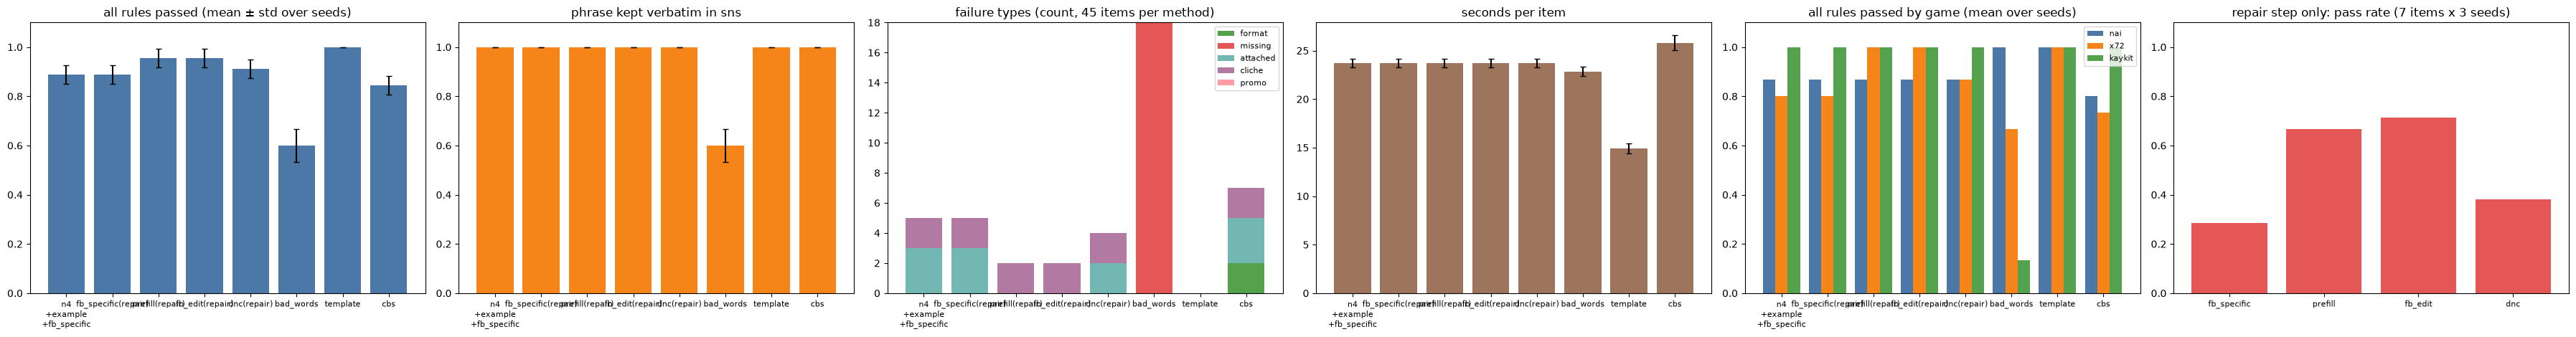

첫 생성에서 검사에 걸린 건 (후보 단계로 간 건)


n  all_rules  n_gen     sec
method                 game                                
bad_words              kaykit  15      0.133  5.867  31.805
                       nai      6      1.000  5.167  23.738
                       x72      9      0.444  5.556  26.232
cbs                    kaykit   9      1.000  5.111  28.540
                       nai      9      0.667  5.333  30.176
                       x72     15      0.733  5.333  29.781
dnc(repair)            kaykit   9      1.000  5.111  33.332
                       nai      9      0.778  5.333  28.150
                       x72     12      0.833  5.250  26.088
fb_edit(repair)        kaykit   9      1.000  5.111  33.332
                       nai      9      0.778  5.333  28.150
                       x72     12      1.000  5.250  26.088
fb_specific(repair)    kaykit   9      1.000  5.111  33.332
                       nai      9      0.778  5.333  28.150
                       x72     12      0.750  5.250  26.088
n4+example+fb_specific kaykit   9      1.000  5.111  33.332
                       nai      9      0.778  5.333  28.150
                       x72     12      0.750  5.250  26.088
prefill(repair)        kaykit   9      1.000  5.111  33.332
                       nai      9      0.778  5.333  28.150
                       x72     12      1.000  5.250  26.088
template               kaykit   3      1.000  5.000  18.197
                       nai      6      1.000  5.000  24.838
                       x72      9      1.000  5.000  21.929

재요청 단계만 다시 만든 결과 (③에서 재요청까지 간 건, 재요청 seed 3개)


size  sum   mean
repair_kind game                    
dnc         kaykit     3    2  0.667
            nai        9    3  0.333
            x72        9    3  0.333
fb_edit     kaykit     3    3  1.000
            nai        9    3  0.333
            x72        9    9  1.000
fb_specific kaykit     3    3  1.000
            nai        9    3  0.333
            x72        9    0  0.000
prefill     kaykit     3    3  1.000
            nai        9    3  0.333
            x72        9    8  0.889

x72_scene_0497 seed 0:


,method,n_gen,sec,all_rules,text
15,n4+example+fb_specific,6,31.90,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."
50,bad_words,1,11.40,True,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."
95,template,5,22.41,True,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서, 마법사와 기사가 함께 ..."
140,cbs,6,34.53,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 친구들과 함께 금화와 보..."
195,fb_specific(repair),6,31.90,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."
240,prefill(repair),6,31.90,True,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."
285,fb_edit(repair),6,31.90,True,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."
330,dnc(repair),6,31.90,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 무기를 들고..."


In [4]:
# 기준 ③: 13(냥기사·0x72) + 10(KayKit) 기록
base = []
for g in TEST_GAMES:
    _b = pd.read_csv(BASE_CSVS[g], keep_default_na=False)
    base.append(_b[(_b.game == g) & (_b.error == '') & (_b.method == BASE_LABEL)])
base = pd.concat(base, ignore_index=True)
new = pd.read_csv(KK_CSV, keep_default_na=False) if KK_CSV.exists() else pd.DataFrame(columns=base.columns)
# 다시 실행해 통과한 건은 오류로 세지 않음 (마지막 기록 기준)
_last = new.drop_duplicates(['method', 'seed', 'item'], keep='last') if len(new) else new
n_err = _last[_last.error != ''].groupby('method').size().to_dict() if len(_last) else {}
print('후보 2·5·6 오류 건수 (마지막 기록 기준):', n_err, '| 첫 실행 포함 전체 오류 기록:',
      new[new.error != ''].groupby('method').size().to_dict() if len(new) else {})
if n_err:
    display(_last[_last.error != ''].drop_duplicates('method')[['method', 'seed', 'item', 'error']])
new = new[new.error == '']
rp = pd.read_csv(REPAIR_CSV, keep_default_na=False) if REPAIR_CSV.exists() else pd.DataFrame()
if len(rp):
    print('재요청 단계 다시 만들기 오류 건수:', int((rp.error != '').sum()))
    rp = rp[rp.error == '']
# 기준과 이번 실행의 이미지·seed가 같은지 확인
_key = lambda d: set(zip(d.game, d['item'], d.seed.astype(int)))
assert _key(base.drop_duplicates(['seed', 'item'])) == {(t['game'], t['item'], s) for t in KK_TASKS_BASE for s in KK_SEEDS}, '기준 기록의 표본이 다름'
# 재요청 단계 후보(1·3·4, ③ 재요청 다시): ③ 결과에서 재요청까지 간 건만 재요청 seed = 그 건의 seed로 바꿔 넣음
_b = base.drop_duplicates(['method', 'seed', 'item'], keep='last')
rep_rows = []
for kind in REPAIR_KINDS:
    if not len(rp):
        break
    _k = rp[(rp.repair_kind == kind) & (rp.repair_seed.astype(int) == rp.seed.astype(int))].drop_duplicates(['item', 'seed'], keep='last')
    _k = _k.assign(seed=_k.seed.astype(int)).set_index(['item', 'seed'])
    _m = _b.copy()
    _m['method'] = kind + '(repair)'
    for i, r in _m.iterrows():
        key = (r['item'], int(r.seed))
        if r.fb_sent != '' and key in _k.index:
            _m.at[i, 'text'] = _k.loc[key, 'text']
    rep_rows.append(_m)
new = pd.concat([new] + rep_rows, ignore_index=True)
print('기준 ③ 건수:', base.drop_duplicates(['seed', 'item']).groupby('game').size().to_dict(),
      '| 이번 건수:', new.drop_duplicates(['method', 'seed', 'item']).groupby('game').size().to_dict())
kk = pd.concat([base.drop_duplicates(['method', 'seed', 'item'], keep='last'),
                new.drop_duplicates(['method', 'seed', 'item'], keep='last')], ignore_index=True)
# 기준(09) 기록에는 재요청 열이 없음
kk['fb_sent'] = kk['fb_sent'].fillna('') if 'fb_sent' in kk else ''
rows = []
for _, r in kk.iterrows():
    s = score_must(r.text, r.game, 'retry')
    rows.append(dict(method=r.method, seed=int(r.seed), item=r['item'], game=r.game, n_gen=int(r.n_gen), sec=float(r.sec_total),
                     fb_used=bool(r.get('fb_sent', '')), text=r.text, **s))
kks = pd.DataFrame(rows)
kks['all_rules'] = kks.format_ok & kks.must_kept & kks.integrated & (kks.promo_violation == False) & (kks.cliche == False)
# 실패 유형 (한 건이 여러 유형에 걸릴 수 있음). 문장 안 넣기는 문구가 들어 있는 경우만 센다
kks['fail_format'] = ~kks.format_ok
kks['fail_missing'] = ~kks.must_kept
kks['fail_attached'] = kks.must_kept & ~kks.integrated
kks['fail_promo'] = kks.promo_violation == True
kks['fail_cliche'] = kks.cliche == True
KK_METHODS = [BASE_LABEL] + [k + '(repair)' for k in REPAIR_KINDS] + [label for label, _, _, _ in FULL_RUNS]
methods = [m for m in KK_METHODS if m in set(kks.method)]

per_seed = kks.groupby(['method', 'seed']).agg(
    format_ok=('format_ok', 'mean'), must_kept=('must_kept', 'mean'), integrated=('integrated', 'mean'),
    cliche=('cliche', 'mean'), all_rules=('all_rules', 'mean'), n_gen=('n_gen', 'mean'), sec=('sec', 'mean'),
    fb_used=('fb_used', 'mean'))
summ = per_seed.groupby('method').agg(['mean', 'std']).reindex(methods)
fails = kks.groupby('method')[['fail_format', 'fail_missing', 'fail_attached', 'fail_promo', 'fail_cliche']].sum()
fails['n_failed'] = (~kks.all_rules).groupby(kks.method).sum()
fails['n'] = kks.groupby('method').size()
fails = fails.reindex(methods)
kks.to_csv(OUT_DIR / 'm25_scored.csv', index=False, encoding='utf-8-sig')
summ.to_csv(OUT_DIR / 'm25_summary.csv', encoding='utf-8-sig')
fails.to_csv(OUT_DIR / 'm25_fail_types.csv', encoding='utf-8-sig')
print('후보별 건수:', kks.groupby('method').size().to_dict())
display(summ.round(3))
by_game = kks.groupby(['method', 'game']).all_rules.mean().unstack().reindex(methods).round(3)
by_game.to_csv(OUT_DIR / 'm25_by_game.csv', encoding='utf-8-sig')
print('게임별 규칙 전부 통과 (seed 3개 평균)')
display(by_game)
print('실패 유형별 건수 (seed 3개 합)')
display(fails)
if KK_RUNS_CSV.exists():
    print('실행 기록 (m25_runs.csv)')
    display(pd.read_csv(KK_RUNS_CSV, keep_default_na=False))

fig, axes = plt.subplots(1, 6, figsize=(36, 4.8))
x = np.arange(len(methods))
names = [m.replace('|', '\n').replace('+', '\n+') for m in methods]
for ax, col, title, color in [(axes[0], 'all_rules', 'all rules passed (mean ± std over seeds)', '#4C78A8'),
                              (axes[1], 'must_kept', 'phrase kept verbatim in sns', '#F58518')]:
    ax.bar(x, summ[(col, 'mean')], yerr=summ[(col, 'std')].fillna(0), capsize=3, color=color)
    ax.set_ylim(0, 1.1)
    ax.set_title(title)
ft = fails[['fail_format', 'fail_missing', 'fail_attached', 'fail_cliche', 'fail_promo']]
bottom = np.zeros(len(methods))
for c, color in zip(ft.columns, ['#54A24B', '#E45756', '#72B7B2', '#B279A2', '#FF9DA6']):
    axes[2].bar(x, ft[c], bottom=bottom, color=color, label=c.replace('fail_', ''))
    bottom += ft[c].values
axes[2].set_title(f'failure types (count, {int(fails.n.iloc[0])} items per method)')
axes[2].legend(fontsize=8)
axes[3].bar(x, summ[('sec', 'mean')], yerr=summ[('sec', 'std')].fillna(0), capsize=3, color='#9D755D')
axes[3].set_title('seconds per item')
for ax in axes[:4]:
    ax.set_xticks(x, names, fontsize=8)
# 게임별 규칙 전부 통과
for k, (g, color) in enumerate(zip(TEST_GAMES, ['#4C78A8', '#F58518', '#54A24B'])):
    axes[4].bar(x + (k - 1) * 0.27, by_game[g].values, 0.27, color=color, label=g)
axes[4].set_xticks(x, names, fontsize=8)
axes[4].set_ylim(0, 1.1)
axes[4].set_title('all rules passed by game (mean over seeds)')
axes[4].legend(fontsize=8)
# 재요청 단계 후보: ③에서 재요청까지 간 건, 재요청 seed 3개 전부의 통과율
if len(rp):
    rp['passed'] = rp.problems == '[]'
    rsum = rp.groupby(['repair_kind', 'game']).passed.agg(['size', 'sum', 'mean']).round(3)
    rsum.to_csv(OUT_DIR / 'm25_repair_summary.csv', encoding='utf-8-sig')
    rk = rp.groupby('repair_kind').passed.mean().reindex(REPAIR_KINDS)
    axes[5].bar(np.arange(len(rk)), rk.values, color='#E45756')
    axes[5].set_xticks(np.arange(len(rk)), rk.index, fontsize=8)
    axes[5].set_ylim(0, 1.1)
    axes[5].set_title(f'repair step only: pass rate ({len(REPAIR_TASKS)} items x {len(REPAIR_SEEDS)} seeds)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'm25_compare.png', dpi=90)
plt.show()

# 첫 생성에서 걸린 건(후보 단계로 간 건)만 놓고 본 통과율과 생성 횟수
went = kks[kks.n_gen > 1]
print('첫 생성에서 검사에 걸린 건 (후보 단계로 간 건)')
display(went.groupby(['method', 'game']).agg(n=('all_rules', 'size'), all_rules=('all_rules', 'mean'),
                                             n_gen=('n_gen', 'mean'), sec=('sec', 'mean')).round(3))
if len(rp):
    print('재요청 단계만 다시 만든 결과 (③에서 재요청까지 간 건, 재요청 seed 3개)')
    display(rsum)
# 21 상세페이지 ②에서 실패한 것과 같은 입력 (0x72 x72_scene_0497, seed 0)
print('x72_scene_0497 seed 0:')
display(kks[(kks['item'] == 'x72_scene_0497.png') & (kks.seed == 0)][['method', 'n_gen', 'sec', 'all_rules', 'text']])


## 이미지·seed별 sns 문장

In [5]:
pd.set_option('display.max_colwidth', 400)
# 보고서용: 이미지·seed별로 후보마다 최종 sns 문장과 통과 여부를 나란히 저장
kks['sns'] = kks.text.map(lambda t: (parse_json(t) or {}).get('sns', ''))
ex = kks.pivot_table(index=['item', 'seed'], columns='method', values='sns', aggfunc='first').reindex(columns=methods)
ok = kks.pivot_table(index=['item', 'seed'], columns='method', values='all_rules', aggfunc='first').reindex(columns=methods)
ex_all = ex.join(ok, rsuffix=' 통과')
ex_all.to_csv(OUT_DIR / 'm25_examples.csv', encoding='utf-8-sig')
print('꼭 넣을 문구:', {g: USER_POINTS[g]['must'] for g in TEST_GAMES})
display(ex_all.xs(0, level='seed'))
print('기준 ③에서 실패한 건의 후보별 sns 문장')
_failed = ok[ok[BASE_LABEL] == False].index
display(ex_all.loc[_failed])
# 구체적 재요청이 실제로 나간 건의 재요청 문장 예시
if len(rp):
    print('재요청 단계 다시 만들기: 방식별 sns 문장 (0x72)')
    rp['sns'] = rp.text.map(lambda t: (parse_json(t) or {}).get('sns', ''))
    display(rp[rp.game == 'x72'][['repair_kind', 'item', 'seed', 'repair_seed', 'passed', 'sns']])

꼭 넣을 문구: {'nai': '11월 업데이트 기념 30% 할인', 'x72': '스팀 찜하기', 'kaykit': '신규 영웅 로그 추가'}


method,n4+example+fb_specific,fb_specific(repair),prefill(repair),fb_edit(repair),dnc(repair),bad_words,template,cbs,n4+example+fb_specific 통과,fb_specific(repair) 통과,prefill(repair) 통과,fb_edit(repair) 통과,dnc(repair) 통과,bad_words 통과,template 통과,cbs 통과
item,,,,,,,,,,,,,,,,
gen_0685_screenshot.png,"빨간 모자와 금화가 날아다니는 풀섬 위, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 신규 동료와 함께 모험을 시작합니다.","빨간 모자와 금화가 날아다니는 풀섬 위, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 신규 동료와 함께 모험을 시작합니다.","빨간 모자와 금화가 날아다니는 풀섬 위, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 신규 동료와 함께 모험을 시작합니다.","빨간 모자와 금화가 날아다니는 풀섬 위, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 신규 동료와 함께 모험을 시작합니다.","빨간 모자와 금화가 날아다니는 풀섬 위, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 신규 동료와 함께 모험을 시작합니다.","빨간 모자와 금화를 향해 뛰는 검은 고양이 기사, 11월 업데이트 기념 30% 할인이 적용됩니다.","붉은 모자를 쓴 고양이 기사가 금화를 따라 달리는 모험, 11월 업데이트 기념 30% 할인으로 더 넓은 세계를 만나 보세요.","빨간 모자와 금화가 날아다니는 풀섬 위, 검은 고양이 기사가 11월 업데이트 기념 30% 할인으로 신규 동료와 함께 모험을 시작합니다.",True,True,True,True,True,True,True,True
gen_0713_screenshot.png,"검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.","검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.",11월 업데이트 기념 30% 할인으로 검은 고양이 기사와 함께 금동 동전 더미를 바라보는 기쁨을 느껴보세요.,"검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.","빨간 모자에 검은 고양이 기사가 금동 동전을 바라보는 순간, 11월 업데이트 기념 30% 할인으로 더 많은 동료와 함께 모험을 시작해 보세요.","검은 고양이 기사가 금동 동전을 바라보는 순간, 11월 업데이트 기념 30% 할인이 시작됩니다.","검은 고양이 기사가 빨간 모자를 쓰고 금동 동전 더미 옆에서 쉬고 있어요, 11월 업데이트 기념 30% 할인으로 더 넓은 세계를 탐험해 보세요.","검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.",False,False,True,False,True,True,True,False
gen_0729_screenshot.png,"빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.","빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.","빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.","빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.","빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.","빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인이 적용된 게임을 지금 만나보세요.","돌담 위에 빨간 모자를 쓴 고양이 기사와 풀숲에 숨은 토끼를 만날 수 있는, 11월 업데이트 기념 30% 할인으로 더 넓은 세계를 탐험해 보세요.","빨간 모자와 녹색 코트를 입은 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.",True,True,True,True,True,True,True,True
gen_0733_screenshot.png,"붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.","붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.","붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.","붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.","붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.","붉은 모자와 검은 털의 고양이 기사가 풀섬의 풍경 속에서 토끼와 마주치는, 11월 업데이트 기념 30% 할인이 적용된 어드벤처 게임입니다.","푸른 하늘 아래 토끼와 함께 걷는 검은 고양이 기사의 여정, 11월 업데이트 기념 30% 할인으로 만나보세요.","붉은 모자와 긴 꼬리를 가진 고양이 기사가 풀밭에서 토끼와 마주치는 순간, 11월 업데이트 기념 30% 할인 중입니다.",True,True,True,True,True,True,True,True
gen_0745_screenshot.png,"붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인으로 신규 동료와 함께할 수 있어요.","붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인으로 신규 동료와 함께할 수 있어요.","붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인으로 신규 동료와 함께할 수 있어요.","붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인으로 신규 동료와 함께할 수 있어요.","붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인으로 신규 동료와 함께할 수 있어요.","붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인이 적용됩니다.","붉은 모자를 쓴 검은 고양이 기사가 성문을 지나는 모험, 11월 업데이트 기념 30% 할인으로 만나보세요.","붉은 모자를 쓴 고양이 기사가 성문 아래 돌แท워 위에 앉아 있는 모습, 11월 업데이트 기념 30% 할인으로 신규 동료와 함께할 수 있어요.",True,True,True,True,True,True,True,True
kk_0142.png,"구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.","구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.","구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.","구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.","구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.","구름 위를 날아다니는 로그, 신규 영웅 로그가 추가되어 전투의 재미를 더해요.","빨간 망토를 휘

기준 ③에서 실패한 건의 후보별 sns 문장


method                                                                            n4+example+fb_specific  \
item                    seed                                                                               
gen_0713_screenshot.png 0     검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.   
                        2                  빨간 모자와 금화 더미, 그리고 친근한 고양이 기사의 여정, 11월 업데이트 기념 30% 할인으로 떠나보세요.   
x72_scene_0310.png      2                             마법사와 기사가 함께 흐르는 불길을 피해 보물상자를 찾아가는 4인 협동 던전, 스팀 찜하기   
x72_scene_0366.png      1                                            마법사가 빨간 망토를 흔들며 금화를 쏟아내는 던전, 스팀 찜하기   
x72_scene_0497.png      0                                  스팀 찜하기, 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.   

method                                                                               fb_specific(repair)  \
item                    seed                                                                               
gen_0713_screenshot.png 0     검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.   
                        2                  빨간 모자와 금화 더미, 그리고 친근한 고양이 기사의 여정, 11월 업데이트 기념 30% 할인으로 떠나보세요.   
x72_scene_0310.png      2                             마법사와 기사가 함께 흐르는 불길을 피해 보물상자를 찾아가는 4인 협동 던전, 스팀 찜하기   
x72_scene_0366.png      1                                            마법사가 빨간 망토를 흔들며 금화를 쏟아내는 던전, 스팀 찜하기   
x72_scene_0497.png      0                                   기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요, 스팀 찜하기   

method                                                                         prefill(repair)  \
item                    seed                                                                     
gen_0713_screenshot.png 0         11월 업데이트 기념 30% 할인으로 검은 고양이 기사와 함께 금동 동전 더미를 바라보는 기쁨을 느껴보세요.   
                        2         11월 업데이트 기념 30% 할인으로 빨간 모자와 금화 더미를 함께할 검은 고양이 기사의 여행을 시작하세요.   
x72_scene_0310.png      2     스팀 찜하기로 4인 협동 던전 탐험, 마법사와 기사가 함께 빛나는 보물상자와 좀비를 물리치는 순간을 경험해 보세요.   
x72_scene_0366.png      1                    스팀 찜하기로 던전의 빨간 망토 마법사와 함께 금화를 쏟아내는 짜릿한 모험을 시작하세요.   
x72_scene_0497.png      0                             스팀 찜하기로 4명이 함께 던전을 헤집으며 금화와 보물상자를 찾아보세요!   

method                                                                                   fb_edit(repair)  \
item                    seed                                                                               
gen_0713_screenshot.png 0     검은 고양이 기사가 금동 동전 더미 앞에서 고개를 돌리는 모습, 11월 업데이트 기념 30% 할인으로 새로운 동료와 함께 떠나보세요.   
                        2                  빨간 모자와 금화 더미, 그리고 친근한 고양이 기사의 여정, 11월 업데이트 기념 30% 할인으로 떠나보세요.   
x72_scene_0310.png      2                   스팀 찜하기로 마법사와 기사가 함께 흐르는 불길을 피해 보물상자를 찾아가는 4인 협동 던전을 경험해 보세요.   
x72_scene_0366.png      1                                  스팀 찜하기로 마법사가 빨간 망토를 흔들며 금화를 쏟아내는 던전을 경험해 보세요.   
x72_scene_0497.png      0                                  스팀 찜하기로 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.   

method                                                                                            dnc(repair)  \
item                    seed                                                                                    
gen_0713_screenshot.png 0     빨간 모자에 검은 고양이 기사가 금동 동전을 바라보는 순간, 11월 업데이트 기념 30% 할인으로 더 많은 동료와 함께 모험을 시작해 보세요.   
                        2                              검은 고양이 기사와 함께 11월 업데이트 기념 30% 할인으로 따뜻한 2D 어드벤처를 즐겨보세요.   
x72_scene_0310.png      2                                        4명이 한 공간에서 금화와 보물상자를 찾아보는 16비트 픽셀 던전, 스팀 찜하기   
x72_scene_0366.png      1                                               픽셀 아트 던전에서 친구들과 함께 마법과 전투를 즐기며 스팀 찜하기   
x72_scene_0497.png      0                                            4명이 한 팀이 되어 던전에서 보물과 싸움을 찾아보는 재미, 스팀 찜하기   

method                                                                                  bad_words  \
item                    seed                                                                        
gen_0713_screenshot.png 0                   검은 고

재요청 단계 다시 만들기: 방식별 sns 문장 (0x72)


,repair_kind,item,seed,repair_seed,passed,sns
36,fb_specific,x72_scene_0497.png,0,0,False,"기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요, 스팀 찜하기"
37,fb_specific,x72_scene_0497.png,0,1,False,"기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요, 스팀 찜하기"
38,fb_specific,x72_scene_0497.png,0,2,False,"기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요, 스팀 찜하기"
39,prefill,x72_scene_0497.png,0,0,True,스팀 찜하기로 4명이 함께 던전을 헤집으며 금화와 보물상자를 찾아보세요!
40,prefill,x72_scene_0497.png,0,1,False,"스팀 찜하기로 4명이 함께 던전을 탐험해보세요. 마법사가 빛나는 마법을 쏘고, 기사가 검으로 적을 막아요."
41,prefill,x72_scene_0497.png,0,2,True,스팀 찜하기로 4명이 함께 던전을 헤집는 재미를 놓치지 마세요.
42,fb_edit,x72_scene_0497.png,0,0,True,스팀 찜하기로 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.
43,fb_edit,x72_scene_0497.png,0,1,True,스팀 찜하기로 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.
44,fb_edit,x72_scene_0497.png,0,2,True,스팀 찜하기로 기사와 마법사가 함께 싸우는 던전에서 금화와 보물상자를 찾아보세요.
45,dnc,x72_scene_0497.png,0,0,False,"4명이 한 팀이 되어 던전에서 보물과 싸움을 찾아보는 재미, 스팀 찜하기"


## 결과

| 후보 | 바꾸는 곳 | KayKit | 냥기사 | 0x72 | 세 게임 평균 | 건당 시간 |
|---|---|---|---|---|---|---|
| 기준 ③ | - | 1.000 | 0.867 | 0.800 | 0.889 | 23.7초 |
| ③ 재요청 다시 만들기 | 재요청 단계 | 1.000 | 0.867 | 0.800 | 0.889 | (③과 같음) |
| 1 `prefill` 미리 채우기 | 재요청 단계 | 1.000 | 0.867 | 1.000 | 0.956 | (③과 같음) |
| 2 `bad_words` 토큰 막기 | 모든 생성 | 0.133 | 1.000 | 0.667 | 0.600 | 22.8초 |
| 3 `fb_edit` 편집 지시 | 재요청 단계 | 1.000 | 0.867 | 1.000 | 0.956 | (③과 같음) |
| 4 `dnc` sns만 다시 쓰기 | 재요청 단계 | 1.000 | 0.867 | 0.867 | 0.911 | (③과 같음) |
| 5 `template` 빈칸 틀 | 지시문 | 1.000 | 1.000 | 1.000 | 1.000 | 14.9초 |
| 6 `cbs` 제약 빔서치 | 첫 생성 | 1.000 | 0.800 | 0.733 | 0.844 | 25.8초 |

- 출처: "지표와 그래프" 셀 표(`m25_by_game.csv`, `m25_summary.csv`). 값은 규칙 전부 통과, 게임마다 5장 × seed 3개 평균이다. 후보 1·3·4의 시간·생성 횟수는 재요청 단계만 바꿔 넣었으므로 ③ 기록과 같다.
- 재요청 단계 후보(1·3·4)의 입력은 ③ 기록에서 다시 고른 재요청 직전 글이고, 이 글로 만든 재요청 문장이 7건 모두 기록과 같았다("생성" 셀).
- 재요청 단계만 따로 보면(③에서 재요청까지 간 7건 × 재요청 seed 3개, `m25_repair_summary.csv`) 0x72는 ③ 재요청 0/9, 미리 채우기 8/9, 편집 지시 9/9, sns만 다시 쓰기 3/9다. 냥기사는 네 방식 모두 3/9다.
- 실패 유형(`m25_fail_types.csv`, 45건 중): ③은 따로 붙음 3·금지 표현 2, 미리 채우기·편집 지시는 금지 표현 2, sns만 다시 쓰기는 따로 붙음 2·금지 표현 2, 토큰 막기는 문구 빠짐 18, 빈칸 틀은 0, 제약 빔서치는 형식 2·따로 붙음 3·금지 표현 2다.
- 빈칸 틀은 생성 횟수가 평균 3.8번에서 2.6번으로 줄었다. 대신 문구 뒤 문장이 비슷해진다. 15건에서 문구 뒤 첫 12글자의 가짓수가 KayKit 10 → 4, 냥기사 8 → 4, 0x72 9 → 10이다(`m25_scored.csv`에서 센 값). KayKit 15건 중 9건이 "…, 신규 영웅 로그 추가로 더 풍부한 전투를 경험해 보세요."다("이미지·seed별 sns 문장" 셀).
- 토큰 막기는 쉼표 뒤 문구를 막자 문구를 아예 쓰지 않는 경우가 늘었다(문구 빠짐 18건).
- 제약 빔서치는 문구가 들어가는 것만 보장하고 위치는 보장하지 않아, 따로 붙는 실패가 그대로 남았다. 첫 실행은 Hub 이름으로 넘겨 45건 모두 OSError였고(Windows에서 함께 쓰는 파일 이름에 역슬래시가 들어감), 코드를 `models/hub_code/constrained-beam-search`에 받아 로컬 경로로 다시 실행했다. 최대 VRAM 18.28GB, seed 하나 411.2~432.1초(`m25_runs.csv`).

결론: 규칙 전부 통과와 시간은 빈칸 틀(세 게임 1.000, 건당 14.9초)이 가장 좋지만, 냥기사·KayKit에서 문구 뒤 표현이 반복된다. 표현 다양성을 기준과 같게 두면서 0x72 실패를 없애는 것은 미리 채우기·편집 지시(0.956, 0x72 1.000)다. 토큰 막기와 제약 빔서치는 기준보다 낮다.

채택 (11/03): 3 `fb_edit` 편집 지시를 앱의 재요청에 쓴다. 미리 채우기와 세 게임 평균은 0.956으로 같지만, ③에서 재요청까지 간 0x72 건에서 편집 지시 9/9, 미리 채우기 8/9다(`m25_repair_summary.csv`). 빈칸 틀은 냥기사·KayKit에서 문구 뒤 표현이 반복돼 쓰지 않는다.